# ATEC'26 - Project C.R.A.T.E.R. - Perception module (Computer Vision)

**Goal:** detect lunar hazards (rocks / craters / ...) locally on CPU, track them, and emit clean detections for the spatial-math teammate.

Pipeline of this notebook:
1. Load + inspect the dataset (YOLO format)
2. Classical CV baseline (fallback + comparison)
3. Fine-tune YOLOv8n
4. Evaluate (precision / recall / mAP)
5. Export to ONNX (+ optional INT8) for CPU edge inference
6. Benchmark (FPS, latency, RAM, model size) - this is what the jury grades
7. `perception.py`: detector + ByteTrack tracker, outputs `ground_px` for the localization step
8. Run on a video and save `detections.jsonl` + annotated video

**Runtime:** use Colab with a GPU for training (Runtime > Change runtime type > T4). Benchmarks should be run on CPU.

## 0. Setup

In [1]:
!pip -q install ultralytics onnxruntime onnx psutil lapx pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 4.2 MB/s eta 0:00:00


In [2]:
import os, time, json, shutil, random, yaml, platform
from pathlib import Path
import numpy as np
import cv2
import psutil
import matplotlib.pyplot as plt
from ultralytics import YOLO

random.seed(0); np.random.seed(0)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
print("Python", platform.python_version(), "| CPU cores:", os.cpu_count())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python 3.13.15 | CPU cores: 2


## 1. Dataset

Put your dataset in **YOLO format** (images + `.txt` label files + `data.yaml`). Choose ONE option below.

- **Option A:** upload the dataset `.zip` to Colab (left sidebar > Files) as `/content/dataset.zip`
- **Option B:** Roboflow download (uncomment and fill in)
- **Option C:** mount Google Drive and point `DATA_YAML` to it
- **Option D (default for the Zenodo lunar rocks & craters dataset):** downloaded automatically if nothing else is found

> The Zenodo dataset is built for *instance segmentation* (polygon labels). We train a **detector** on it: Ultralytics converts the polygons to bounding boxes automatically, and boxes are all the rest of the pipeline needs (the bottom-center pixel of each box goes to the localization step). Segmentation masks would cost more CPU for little gain here.

In [3]:
DATA_ROOT = Path("/content/dataset")
DATA_ROOT.mkdir(exist_ok=True)

# ---- Option A: zip uploaded to Colab ----
ZIP_PATH = Path("/content/dataset.zip")
if ZIP_PATH.exists():
    !unzip -q -o {ZIP_PATH} -d {DATA_ROOT}

# ---- Option B: Roboflow (uncomment) ----
# !pip -q install roboflow
# from roboflow import Roboflow
# rf = Roboflow(api_key="YOUR_KEY")
# ds = rf.workspace("WORKSPACE").project("PROJECT").version(1).download("yolov8", location=str(DATA_ROOT))

# ---- Option C: Google Drive (uncomment) ----
# from google.colab import drive; drive.mount("/content/drive")
# DATA_ROOT = Path("/content/drive/MyDrive/YOUR_DATASET_FOLDER")

# ---- Option D: Zenodo lunar rocks & craters dataset (YOLO zip, 187 MB) - downloads directly in Colab ----
if not any(DATA_ROOT.rglob("*.yaml")) and not any(DATA_ROOT.rglob("train")):
    !wget -q -O /content/Dataset_yolo.zip "https://zenodo.org/records/14673237/files/Dataset_yolo.zip?download=1"
    !unzip -q -o /content/Dataset_yolo.zip -d {DATA_ROOT}

!find {DATA_ROOT} -maxdepth 3 | head -30     # look at the folder structure

found = sorted(DATA_ROOT.rglob("data.yaml")) or sorted(DATA_ROOT.rglob("*.yaml"))
if found:
    DATA_YAML_RAW = found[0]
else:
    # No yaml in the zip -> build one from the folder structure. VERIFY the class order with the sample plot below
    # (craters = large circular depressions, rocks = small blobs). If swapped, swap the names here.
    roots = [p.parent for p in DATA_ROOT.rglob("train") if p.is_dir()]
    assert roots, "Could not find a 'train' folder. Check the dataset structure printed above."
    DATA_YAML_RAW = roots[0] / "data.yaml"
    DATA_YAML_RAW.write_text(yaml.safe_dump({"path": str(roots[0]), "train": "train/images", "val": "val/images",
                                             "names": {0: "rock", 1: "crater"}}))
print("Using:", DATA_YAML_RAW)

/content/dataset
/content/dataset/Dataset_yolo
/content/dataset/Dataset_yolo/data.yaml
/content/dataset/Dataset_yolo/test
/content/dataset/Dataset_yolo/test/labels
/content/dataset/Dataset_yolo/test/images
/content/dataset/Dataset_yolo/train
/content/dataset/Dataset_yolo/train/labels
/content/dataset/Dataset_yolo/train/images
/content/dataset/Dataset_yolo/train/labels.cache
/content/dataset/Dataset_yolo/valid
/content/dataset/Dataset_yolo/valid/labels
/content/dataset/Dataset_yolo/valid/images
/content/dataset/Dataset_yolo/valid/labels.cache
Using: /content/dataset/Dataset_yolo/data.yaml


In [4]:
def fix_yaml(yaml_path):
    """Roboflow/Kaggle yamls often have broken relative paths. Rewrite with absolute, verified ones."""
    yaml_path = Path(yaml_path); root = yaml_path.parent
    cfg = yaml.safe_load(yaml_path.read_text())
    cands = {
        "train": ["train/images", "images/train", "train"],
        "val":   ["valid/images", "val/images", "images/val", "images/valid", "valid", "val"],
        "test":  ["test/images", "images/test", "test"],
    }
    for split, alts in cands.items():
        hit = next((a for a in alts if (root / a).exists()), None)
        if hit: cfg[split] = hit
        else:   cfg.pop(split, None)
    if "val" not in cfg:
        print("WARNING: no validation split found -> using train as val (metrics will be optimistic!)")
        cfg["val"] = cfg["train"]
    cfg["path"] = str(root.resolve())
    names = cfg.get("names", {})
    cfg["names"] = {i: n for i, n in enumerate(names)} if isinstance(names, list) else {int(k): v for k, v in names.items()}
    cfg["nc"] = len(cfg["names"])
    out = root / "data_fixed.yaml"
    out.write_text(yaml.safe_dump(cfg, sort_keys=False))
    return out, cfg

DATA_YAML, CFG = fix_yaml(DATA_YAML_RAW)
CLASS_NAMES = CFG["names"]
print("data yaml:", DATA_YAML)
print("classes  :", CLASS_NAMES)

data yaml: /content/dataset/Dataset_yolo/data_fixed.yaml
classes  : {0: 'crater', 1: 'rock'}


train:  7734 images | empty labels: 30 | boxes per class: {'crater': 6352, 'rock': 15097}
val  :   313 images | empty labels: 0 | boxes per class: {'crater': 219, 'rock': 738}
test :   307 images | empty labels: 0 | boxes per class: {'crater': 143, 'rock': 879}


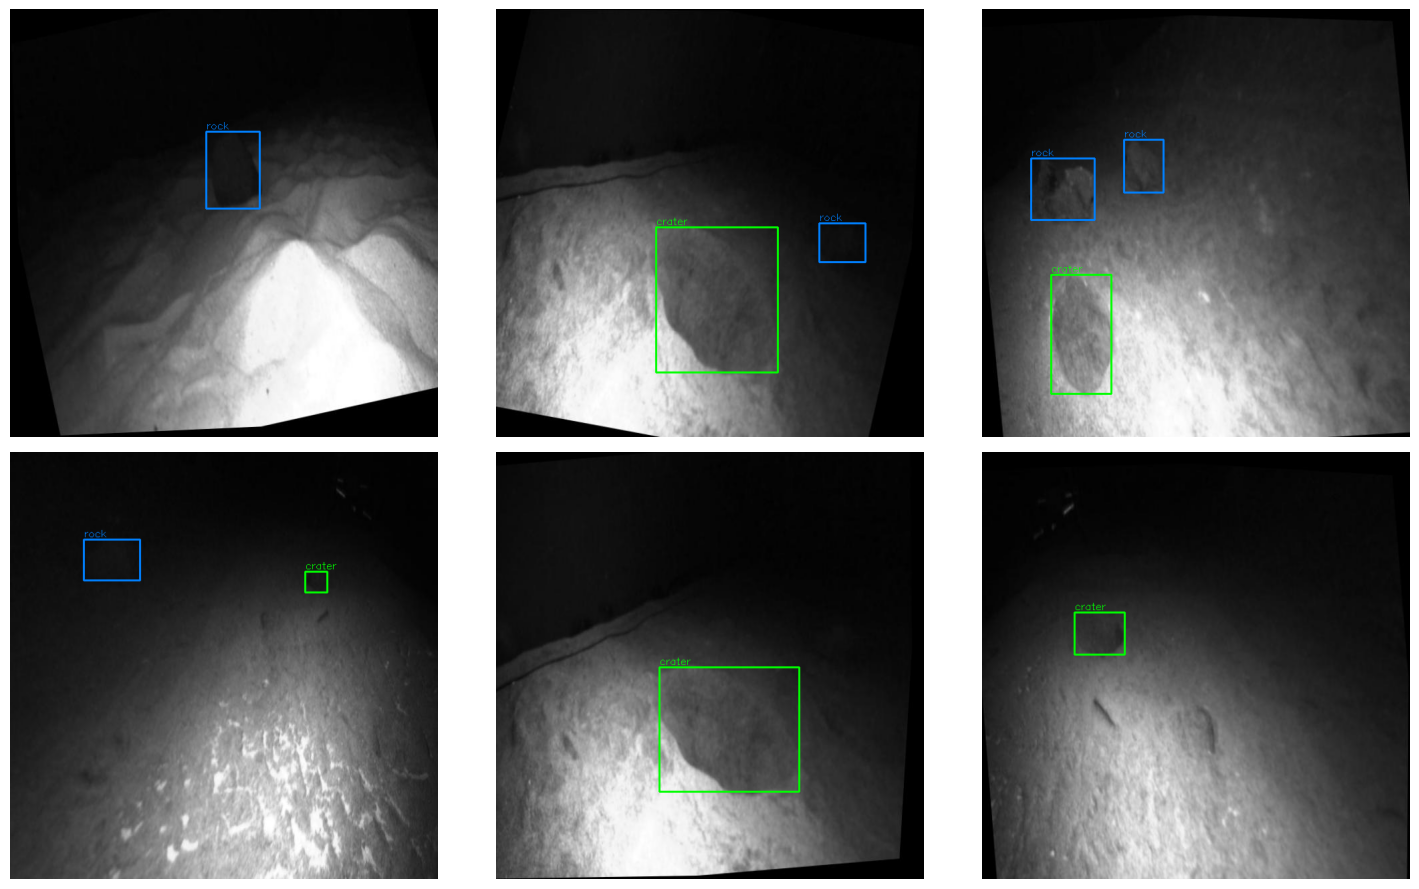

In [5]:
def split_dir(split):
    return Path(CFG["path"]) / CFG[split]

def list_images(split):
    d = split_dir(split)
    return sorted(p for p in d.rglob("*") if p.suffix.lower() in IMG_EXT)

def read_boxes(lp):
    """Read a YOLO label file -> list of (cls, xc, yc, w, h), normalized.
    Handles BOTH box rows (5 values) and segmentation polygon rows (cls x1 y1 x2 y2 ...)."""
    out = []
    if not Path(lp).exists(): return out
    for l in Path(lp).read_text().strip().splitlines():
        p = l.split()
        if len(p) < 5: continue
        c, v = int(float(p[0])), list(map(float, p[1:]))
        if len(v) == 4:
            out.append((c, *v))
        else:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            out.append((c, (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1))
    return out

def label_path(img_path):
    s = str(img_path).replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep)
    return Path(s).with_suffix(".txt")

# --- dataset stats ---
for split in ["train", "val", "test"]:
    if split in CFG:
        imgs = list_images(split)
        counts = {n: 0 for n in CLASS_NAMES.values()}; empty = 0
        for p in imgs:
            rows = read_boxes(label_path(p))
            if not rows: empty += 1
            for r in rows:
                counts[CLASS_NAMES[r[0]]] += 1
        print(f"{split:5s}: {len(imgs):5d} images | empty labels: {empty} | boxes per class: {counts}")

# --- visualize labeled samples ---
def draw_gt(img_path):
    img = cv2.imread(str(img_path)); h, w = img.shape[:2]
    for c, xc, yc, bw, bh in read_boxes(label_path(img_path)):
        x1, y1, x2, y2 = int((xc-bw/2)*w), int((yc-bh/2)*h), int((xc+bw/2)*w), int((yc+bh/2)*h)
        col = (0, 255, 0) if c == 0 else (255, 128, 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), col, 2)
        cv2.putText(img, CLASS_NAMES[c], (x1, max(12, y1-4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 1)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

sample = random.sample(list_images("train"), 6)
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axs.ravel(), sample):
    ax.imshow(draw_gt(p)); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Classical CV baseline

No training needed, very fast. Useful as (a) a **fallback if the ML model fails in the live demo**, and (b) a comparison row in the benchmark table.
Key idea for lunar scenes: CLAHE to recover contrast, then detect dark shadow regions and bright edges and filter contours by size/shape.

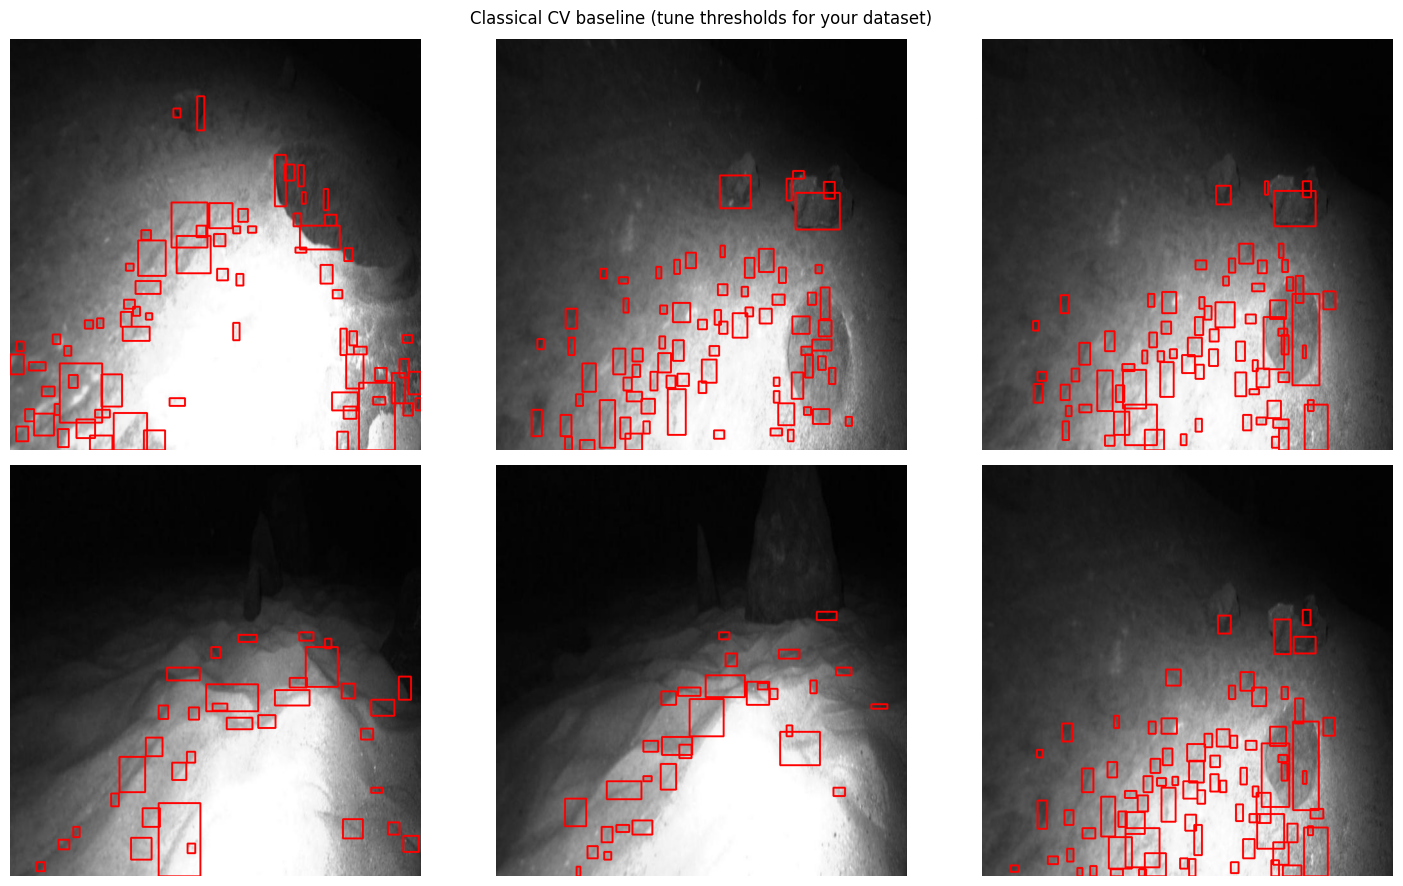

In [6]:
def classical_detect(frame, min_area=60, max_area_frac=0.25):
    """Returns list of dicts: bbox=[x1,y1,x2,y2], conf (heuristic), cls=0."""
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    g = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(gray)
    g = cv2.GaussianBlur(g, (5, 5), 0)
    th = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 12)
    k = np.ones((3, 3), np.uint8)
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN, k)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    H, W = gray.shape; dets = []
    for c in cnts:
        a = cv2.contourArea(c)
        if a < min_area or a > max_area_frac * H * W: continue
        x, y, w, h = cv2.boundingRect(c)
        if not (0.2 < w / max(h, 1) < 5): continue
        solidity = a / max(cv2.contourArea(cv2.convexHull(c)), 1)
        dets.append({"bbox": [x, y, x + w, y + h], "conf": float(min(1.0, solidity)), "cls": 0})
    return dets

val_imgs = list_images("val")
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axs.ravel(), random.sample(val_imgs, min(6, len(val_imgs)))):
    im = cv2.imread(str(p))
    for d in classical_detect(im):
        x1, y1, x2, y2 = d["bbox"]; cv2.rectangle(im, (x1, y1), (x2, y2), (0, 0, 255), 2)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.axis("off")
plt.suptitle("Classical CV baseline (tune thresholds for your dataset)"); plt.tight_layout(); plt.show()

## 3. Fine-tune YOLOv8n

`yolov8n` (about 3M params) is the smallest YOLO, which suits the "constrained compute" requirement. Augmentations target lunar conditions (harsh lighting changes, low contrast, grayscale-like imagery).

If the result is weak: more epochs, bigger `IMGSZ` (e.g. 640), or `yolov8s`. Justify the trade-off with the benchmark below.

In [7]:
EPOCHS = 60
IMGSZ  = 416        # smaller = faster on CPU. Try 320 / 416 / 640 and compare in the benchmark
BATCH  = 16
BASE   = "yolov8n.pt"

model = YOLO(BASE)
results = model.train(
    data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    patience=15, project="runs", name="crater", exist_ok=True,
    # lunar-oriented augmentation
    hsv_h=0.0, hsv_s=0.1, hsv_v=0.5,     # strong brightness change, little color (lunar is nearly grayscale)
    degrees=10, translate=0.1, scale=0.5, fliplr=0.5, flipud=0.0,
    mosaic=1.0, close_mosaic=10, seed=0,
)
BEST_PT = Path(model.trainer.best)
print("best weights:", BEST_PT)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/Dataset_yolo/data_fixed.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.1, hsv_v=0.5, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=crater, nbs=64, nms=None, opset=None, optimize=F

## 4. Evaluation

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 837.4±221.8 MB/s, size: 22.6 KB)
val: Scanning /content/dataset/Dataset_yolo/valid/labels.cache... 313 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 313/313 87.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 5.0it/s 4.0s
                   all        313        957      0.954      0.942      0.978       0.91
Speed: 1.0ms preprocess, 3.0ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val
precision=0.954  recall=0.942  mAP50=0.978  mAP50-95=0.910
  crater       AP50=0.978
  rock         AP50=0.978


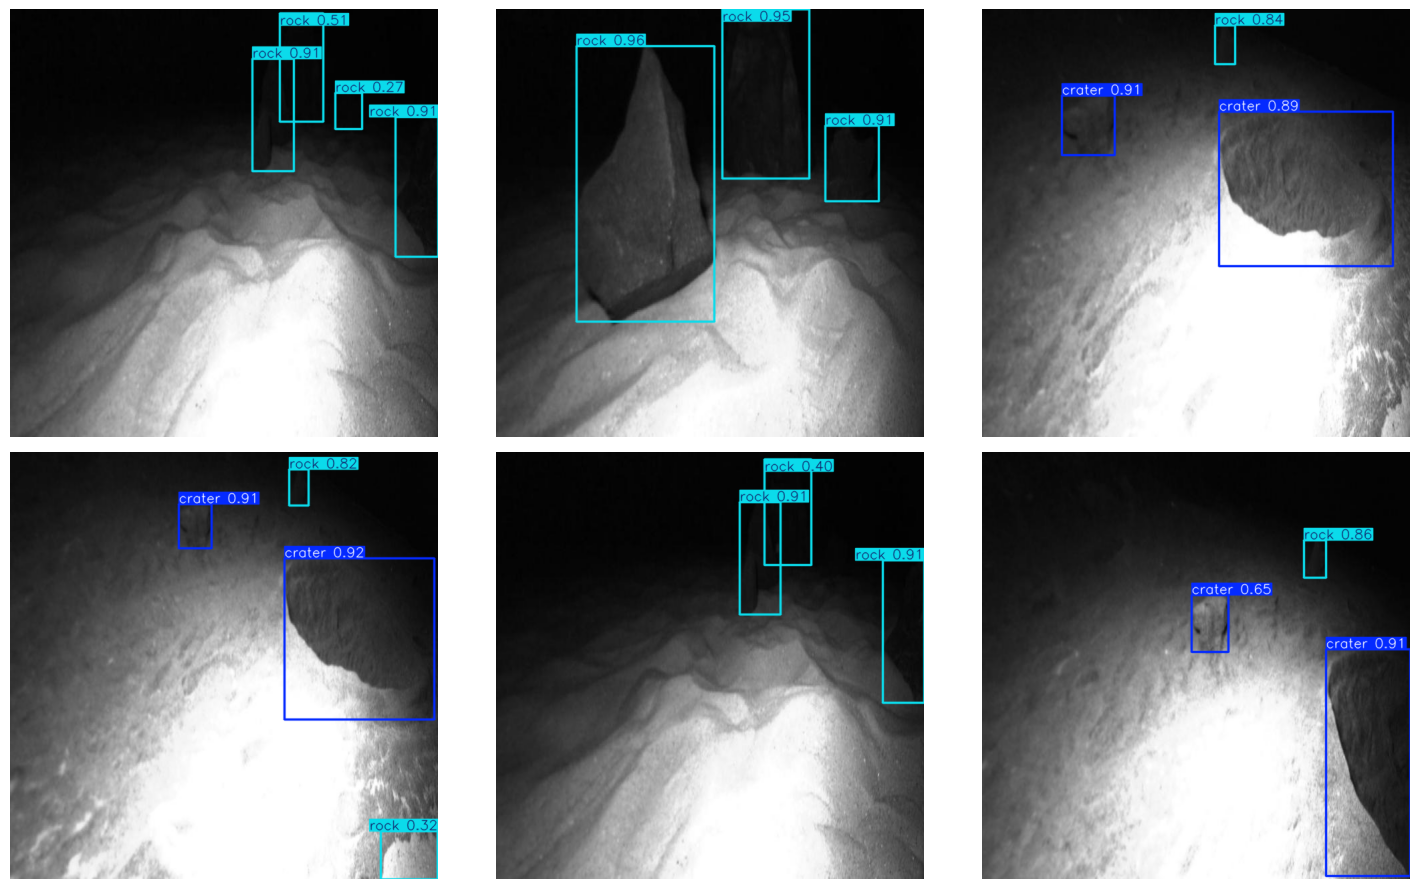

In [8]:
best = YOLO(str(BEST_PT))
m = best.val(data=str(DATA_YAML), imgsz=IMGSZ, split="val", verbose=False)
print(f"precision={m.box.mp:.3f}  recall={m.box.mr:.3f}  mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}")
for i, name in enumerate(m.names.values()):
    try: print(f"  {name:12s} AP50={m.box.ap50[i]:.3f}")
    except Exception: pass

# Predictions on a few validation images
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axs.ravel(), random.sample(val_imgs, min(6, len(val_imgs)))):
    r = best.predict(str(p), imgsz=IMGSZ, conf=0.25, verbose=False, device="cpu")[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Export to ONNX (CPU edge inference)

ONNX Runtime on CPU = no GPU, no cloud, small dependency footprint. We also try **INT8 dynamic quantization** (smaller file, sometimes faster); keep it only if the benchmark shows it helps and accuracy holds.

In [9]:
ONNX_FP32 = Path(best.export(format="onnx", imgsz=IMGSZ, simplify=True, dynamic=False, opset=12))
print("FP32:", ONNX_FP32, f"{ONNX_FP32.stat().st_size/1e6:.1f} MB")

ONNX_INT8 = None
try:
    from onnxruntime.quantization import quantize_dynamic, QuantType
    ONNX_INT8 = ONNX_FP32.with_name(ONNX_FP32.stem + "_int8.onnx")
    quantize_dynamic(str(ONNX_FP32), str(ONNX_INT8), weight_type=QuantType.QUInt8)
    print("INT8:", ONNX_INT8, f"{ONNX_INT8.stat().st_size/1e6:.1f} MB")
except Exception as e:
    print("INT8 quantization skipped:", e)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 3.7 GFLOPs

PyTorch: starting from '/content/runs/detect/runs/crater/weights/best.pt' with input shape (1, 3, 416, 416) BCHW and output shape(s) (1, 6, 3549) (6.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 10 packages in 315ms
Prepared 2 packages in 27ms
Installed 2 packages in 6ms
 + colorama==0.4.6
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.3s, saved as '/content/runs/det

FP32: /content/runs/detect/runs/crater/weights/best.onnx 12.7 MB
INT8: /content/runs/detect/runs/crater/weights/best_int8.onnx 3.4 MB


## 6. Benchmark (CPU)

Measures per-frame latency, FPS, p95 latency, extra RAM, and model size. Run this on CPU: in Colab set the runtime to CPU, or just trust the `device="cpu"` flag below. **For the final numbers, re-run on the machine you will demo on.**

In [10]:
import torch
torch.set_num_threads(max(1, (os.cpu_count() or 2) // 1))
proc = psutil.Process(os.getpid())

BENCH_FRAMES = [cv2.imread(str(p)) for p in (val_imgs * 5)[:100]]

def bench(name, predict_fn, model_path=None, warmup=10):
    for f in BENCH_FRAMES[:warmup]: predict_fn(f)
    rss0 = proc.memory_info().rss
    lat = []
    for f in BENCH_FRAMES:
        t = time.perf_counter(); predict_fn(f); lat.append((time.perf_counter() - t) * 1000)
    lat = np.array(lat)
    return {
        "model": name,
        "FPS": round(1000 / lat.mean(), 1),
        "lat_ms_mean": round(lat.mean(), 1),
        "lat_ms_p95": round(np.percentile(lat, 95), 1),
        "RAM_MB_delta": round((proc.memory_info().rss - rss0) / 1e6, 1),
        "size_MB": round(Path(model_path).stat().st_size / 1e6, 2) if model_path else 0.0,
    }

rows = [bench("Classical CV", classical_detect)]
yolo_fp32 = YOLO(str(ONNX_FP32), task="detect")
rows.append(bench(f"YOLOv8n ONNX FP32 @{IMGSZ}", lambda f: yolo_fp32.predict(f, imgsz=IMGSZ, conf=0.25, device="cpu", verbose=False), ONNX_FP32))
if ONNX_INT8:
    try:
        yolo_int8 = YOLO(str(ONNX_INT8), task="detect")
        rows.append(bench(f"YOLOv8n ONNX INT8 @{IMGSZ}", lambda f: yolo_int8.predict(f, imgsz=IMGSZ, conf=0.25, device="cpu", verbose=False), ONNX_INT8))
    except Exception as e:
        print("INT8 model could not run:", e)

import pandas as pd
bench_df = pd.DataFrame(rows); display(bench_df)
bench_df.to_csv("benchmark_perception.csv", index=False)

Loading /content/runs/detect/runs/crater/weights/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CPUExecutionProvider
Loading /content/runs/detect/runs/crater/weights/best_int8.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CPUExecutionProvider


,model,FPS,lat_ms_mean,lat_ms_p95,RAM_MB_delta,size_MB
0,Classical CV,118.0,8.5,9.5,0.1,0.00
1,YOLOv8n ONNX FP32 @416,20.9,48.0,51.1,0.0,12.68
2,YOLOv8n ONNX INT8 @416,11.7,85.5,112.4,0.7,3.39


## 7. `perception.py` - the module the rest of the team imports

Detector (ONNX, CPU) + **ByteTrack** tracker. Each hazard gets a persistent `track_id`; `new=True` fires once when a track is confirmed (seen in `confirm_frames` frames), so downstream modules transmit each hazard **once** instead of every frame.

`ground_px = (x_center, y_bottom)` of the bounding box is the pixel touching the ground. The spatial-math teammate back-projects that point.

In [19]:
%%writefile perception.py
"""Perception module for C.R.A.T.E.R. - local CPU detector + tracker.

Usage:
    from perception import Perception
    p = Perception()
    out = p.process(frame_bgr, ts)   # -> {"t": ts, "frame": n, "dets": [...]}
"""
import time
from ultralytics import YOLO


class Perception:
    def __init__(self, weights="/content/runs/detect/runs/crater/weights/best.onnx", imgsz=416, conf=0.25, iou=0.5, confirm_frames=3, tracker="bytetrack.yaml"):
        self.model = YOLO(weights, task="detect")
        self.imgsz, self.conf, self.iou = imgsz, conf, iou
        self.confirm_frames, self.tracker = confirm_frames, tracker
        self.seen, self.reported, self.n = {}, set(), 0

    def process(self, frame, ts=None):
        ts = time.time() if ts is None else ts
        r = self.model.track(frame, persist=True, tracker=self.tracker, imgsz=self.imgsz,
                             conf=self.conf, iou=self.iou, device="cpu", verbose=False)[0]
        dets = []
        if r.boxes is not None and r.boxes.id is not None:
            ids = r.boxes.id.int().tolist()
            xyxy = r.boxes.xyxy.tolist()
            cls = r.boxes.cls.int().tolist()
            conf = r.boxes.conf.tolist()
            for tid, b, c, p in zip(ids, xyxy, cls, conf):
                self.seen[tid] = self.seen.get(tid, 0) + 1
                is_new = self.seen[tid] >= self.confirm_frames and tid not in self.reported
                if is_new:
                    self.reported.add(tid)
                dets.append({
                    "track_id": tid,
                    "cls": c,
                    "name": r.names[c],
                    "conf": round(p, 3),
                    "bbox": [round(v, 1) for v in b],
                    "ground_px": [round((b[0] + b[2]) / 2, 1), round(b[3], 1)],
                    "new": is_new,
                })
        self.n += 1
        return {"t": ts, "frame": self.n, "dets": dets}

Overwriting perception.py


## 8. Run on a video

Set `VIDEO_PATH` to the mission clip (or any lunar test video). If it doesn't exist, a test video is built from the validation images so you can still test the full flow.

Loading /content/runs/detect/runs/crater/weights/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CPUExecutionProvider
frames: 150 | mean FPS: 16.5 | p95 latency: 82.4 ms
unique hazards confirmed (transmit once each): 27 | confirmed-new events: 27


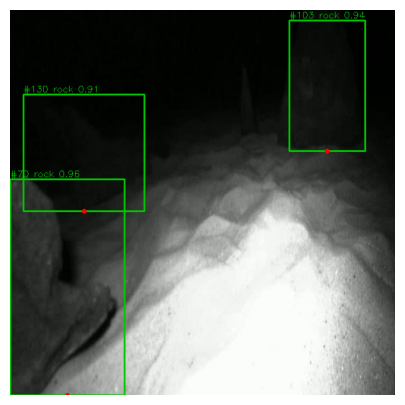

In [17]:
VIDEO_PATH = Path("/content/test_video.mp4")
WEIGHTS    = str(ONNX_FP32)                      # or str(ONNX_INT8) if it won the benchmark

if not VIDEO_PATH.exists():
    print("No video found -> building a test video from validation images")
    first = cv2.imread(str(val_imgs[0])); H, W = first.shape[:2]
    vw = cv2.VideoWriter(str(VIDEO_PATH), cv2.VideoWriter_fourcc(*"mp4v"), 10, (W, H))
    for p in val_imgs[:150]:
        vw.write(cv2.resize(cv2.imread(str(p)), (W, H)))
    vw.release()

import importlib, perception; importlib.reload(perception)
from perception import Perception

per = Perception(WEIGHTS, imgsz=IMGSZ, conf=0.25, confirm_frames=3)
cap = cv2.VideoCapture(str(VIDEO_PATH))
fps_in = cap.get(cv2.CAP_PROP_FPS) or 10
W, H = int(cap.get(3)), int(cap.get(4))
writer = cv2.VideoWriter("annotated.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps_in, (W, H))

n, lat, new_events = 0, [], 0
last_valid_frame = None

with open("detections.jsonl", "w") as fout:
    while True:
        ok, frame = cap.read()
        if not ok: break
        t0 = time.perf_counter()
        out = per.process(frame, ts=n / fps_in)
        lat.append((time.perf_counter() - t0) * 1000)
        fout.write(json.dumps(out) + "\n")
        for d in out["dets"]:
            x1, y1, x2, y2 = map(int, d["bbox"])
            col = (0, 255, 255) if d["new"] else (0, 200, 0)
            cv2.rectangle(frame, (x1, y1), (x2, y2), col, 2)
            cv2.circle(frame, tuple(map(int, d["ground_px"])), 4, (0, 0, 255), -1)
            cv2.putText(frame, f'#{d["track_id"]} {d["name"]} {d["conf"]:.2f}', (x1, max(12, y1 - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 1)
            new_events += d["new"]
        writer.write(frame)
        last_valid_frame = frame.copy()
        n += 1
cap.release(); writer.release()

lat = np.array(lat)
print(f"frames: {n} | mean FPS: {1000/lat.mean():.1f} | p95 latency: {np.percentile(lat,95):.1f} ms")
print(f"unique hazards confirmed (transmit once each): {len(per.reported)} | confirmed-new events: {new_events}")

if last_valid_frame is not None:
    plt.figure(figsize=(8, 5)); plt.imshow(cv2.cvtColor(last_valid_frame, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
else:
    print("No frames were successfully processed.")

## 9. Save artifacts for the team / repo

Give these to the teammates: `perception.py`, the ONNX weights, `benchmark_perception.csv`, `detections.jsonl` (sample output to develop the localization/telemetry modules against).

In [18]:
OUT = Path("perception_export"); OUT.mkdir(exist_ok=True)
for f in ["perception.py", "benchmark_perception.csv", "detections.jsonl", "annotated.mp4", str(ONNX_FP32), str(BEST_PT)]:
    if Path(f).exists(): shutil.copy(f, OUT / Path(f).name)
if ONNX_INT8 and Path(ONNX_INT8).exists(): shutil.copy(ONNX_INT8, OUT / Path(ONNX_INT8).name)
(OUT / "classes.json").write_text(json.dumps(CLASS_NAMES, indent=2))
shutil.make_archive("perception_export", "zip", OUT)
print("Created perception_export.zip:", sorted(p.name for p in OUT.iterdir()))
try:
    from google.colab import files; files.download("perception_export.zip")
except Exception:
    pass

Created perception_export.zip: ['annotated.mp4', 'benchmark_perception.csv', 'best.onnx', 'best.pt', 'best_int8.onnx', 'classes.json', 'detections.jsonl', 'perception.py']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>